In [8]:
#imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

### Clean data and create datasets

In [9]:
#this cell just cleaned up some slight formatting issues, but it is a permanent
#change that does not need to be run over and over

# folder = Path("raw beacon data")
# sensor_ids = [i for i in range(2,26) if i!= 17]

# for i in sensor_ids:
#     path = folder / f"Sensor{i:02d}raw.csv"

#     if not path.exists():
#         print(f"Skipping {path.name}: file not found")
#         continue

#     df = pd.read_csv(path)
#     df["datetime"] = pd.to_datetime(df["datetime"], format="%m/%d/%y %H:%M")
#     df = df.rename(columns={"datetime": "datetime_utc"})
#     df["datetime_utc"] = df["datetime_utc"].dt.strftime("%Y-%m-%d %H:%M:%S")

#     df.to_csv(path, index=False)
#     print(f"Updated {path.name}")

### Identify low RSD data

RSD Cutoff (10th percentile): 4.36%
Low RSD hours: 453 of 4523


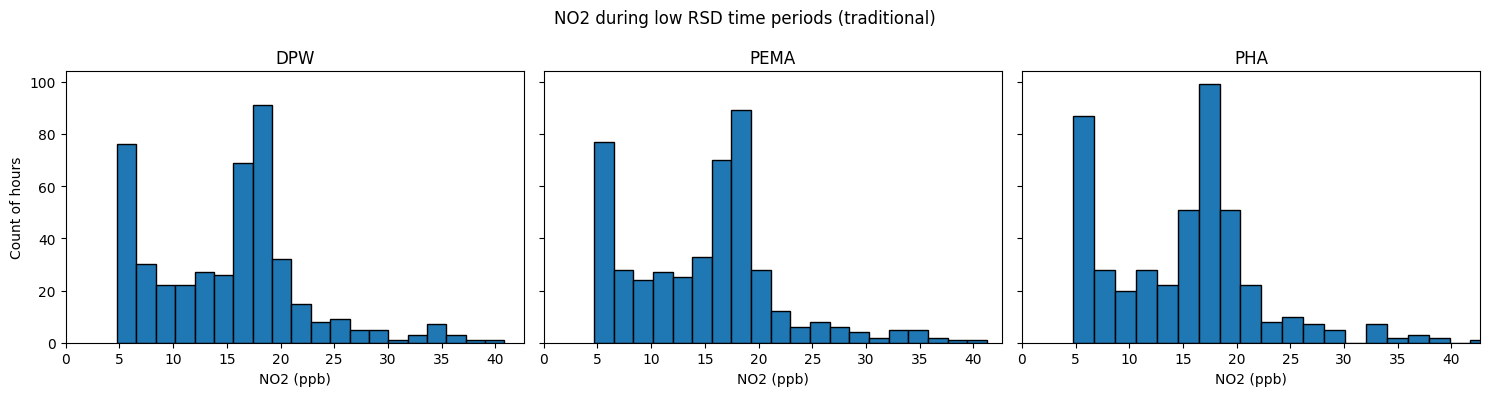

In [10]:
#traditional low RSD approach
ref_folder = Path("raw quant recalibrated data")
out_folder = Path("traditional low RSD data")
sites = ["dpw", "pema", "pha"]

dfs = []
for site in sites:
    d = pd.read_csv(ref_folder / f"{site}_2025_cleaned.csv", parse_dates=["datetime_utc"])
    d = d.rename(columns={"no2": f"{site}_no2"})
    dfs.append(d)

#only keep hours where all three sites have data
merged = dfs[0]
for d in dfs[1:]:
    merged = merged.merge(d, on="datetime_utc", how="inner")
merged = merged.dropna()

no2_cols = [f"{s}_no2" for s in sites]
merged["rsd_pct"] = merged[no2_cols].std(axis=1, ddof=1) / merged[no2_cols].mean(axis=1) * 100

cutoff = merged["rsd_pct"].quantile(0.10)
low_rsd = merged[merged["rsd_pct"] <= cutoff].copy()
print(f"RSD Cutoff (10th percentile): {cutoff:.2f}%")
print(f"Low RSD hours: {len(low_rsd)} of {len(merged)}")

low_rsd["datetime_utc"] = low_rsd["datetime_utc"].dt.strftime("%Y-%m-%d %H:%M:%S")
low_rsd.to_csv(out_folder / "low_rsd_hours.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15,4), sharex=True, sharey=True)
for ax, site in zip(axes, sites):
    ax.hist(low_rsd[f"{site}_no2"], bins=20, edgecolor="black")
    ax.set_xlim(left=0)
    ax.set_title(f"{site.upper()}")
    ax.set_xlabel("NO2 (ppb)")

axes[0].set_ylabel("Count of hours")
fig.suptitle("NO2 during low RSD time periods (traditional)")
plt.tight_layout()
plt.show()

RSD cutoff, avg >= 15 ppb: 2.98%  (141 of 1403 hours)
RSD cutoff, avg <  15 ppb: 5.70%  (312 of 3120 hours)


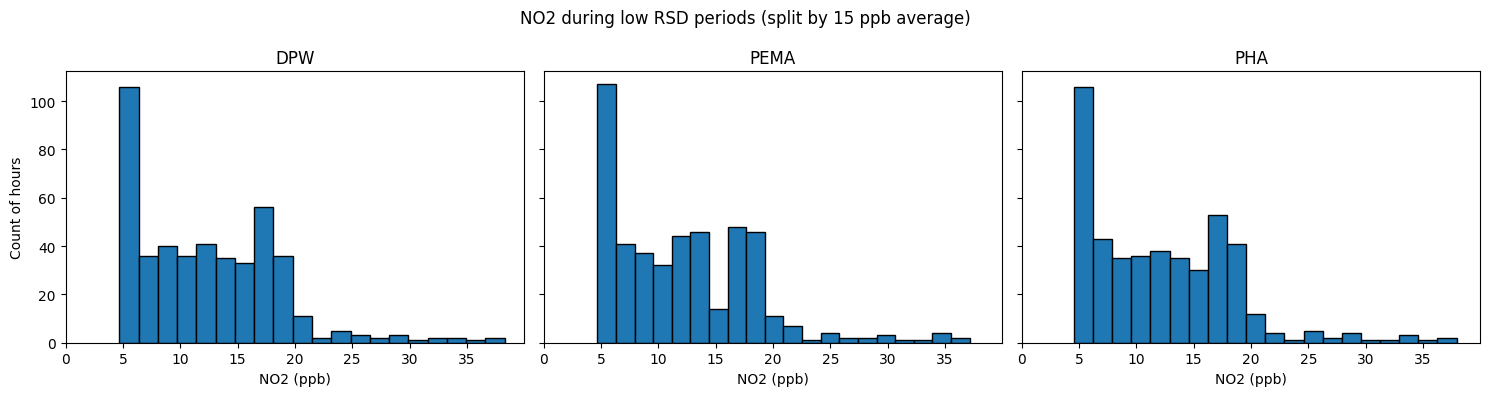

In [11]:
#data split RSD approach
ref_folder = Path("raw quant recalibrated data")
out_folder = Path("new low RSD data")
sites = ["dpw", "pema", "pha"]
threshold = 15

dfs = []
for site in sites:
    d = pd.read_csv(ref_folder / f"{site}_2025_cleaned.csv", parse_dates=["datetime_utc"])
    d = d.rename(columns={"no2": f"{site}_no2"})
    dfs.append(d)

merged = dfs[0]
for d in dfs[1:]:
    merged = merged.merge(d, on="datetime_utc", how="inner")
merged = merged.dropna()

no2_cols = [f"{s}_no2" for s in sites]
merged["avg_no2"] = merged[no2_cols].mean(axis=1)
merged["rsd_pct"] = merged[no2_cols].std(axis=1, ddof=1) / merged["avg_no2"] * 100

high = merged[merged["avg_no2"] >= threshold].copy()
low = merged[merged["avg_no2"] < threshold].copy()

cutoff_high = high["rsd_pct"].quantile(0.10)
cutoff_low = low["rsd_pct"].quantile(0.10)

high_sel = high[high["rsd_pct"] <= cutoff_high].copy()
high_sel["group"] = f">={threshold} ppb"
low_sel = low[low["rsd_pct"] <= cutoff_low].copy()
low_sel["group"] = f"<{threshold} ppb"

print(f"RSD cutoff, avg >= {threshold} ppb: {cutoff_high:.2f}%  ({len(high_sel)} of {len(high)} hours)")
print(f"RSD cutoff, avg <  {threshold} ppb: {cutoff_low:.2f}%  ({len(low_sel)} of {len(low)} hours)")

low_rsd = pd.concat([low_sel, high_sel]).sort_values("datetime_utc")
out = low_rsd[["datetime_utc"] + no2_cols + ["rsd_pct", "group"]].copy()
out["datetime_utc"] = out["datetime_utc"].dt.strftime("%Y-%m-%d %H:%M:%S")
out.to_csv(out_folder / "low_rsd_hours.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, site in zip(axes, sites):
    ax.hist(low_rsd[f"{site}_no2"], bins=20, edgecolor="black")
    ax.set_xlim(left=0)
    ax.set_title(f"{site.upper()}")
    ax.set_xlabel("NO2 (ppb)")
axes[0].set_ylabel("Count of hours")
fig.suptitle("NO2 during low RSD periods (split by 15 ppb average)")
plt.tight_layout()
plt.show()

In [12]:
beacon_folder = Path("raw beacon data")
ref_folder = Path("raw quant recalibrated data")
out_folder = Path("training and testing datasets")

low_rsd_path = Path("traditional low RSD data") / "low_rsd_hours.csv"

sensor_to_site = {
    "Sensor03": "dpw", "Sensor08": "dpw", "Sensor09": "dpw", "Sensor14": "dpw",
    "Sensor16": "dpw", "Sensor18": "dpw", "Sensor21": "dpw",
    "Sensor01": "mjf", "Sensor17": "mjf",
    "Sensor05": "pema", "Sensor06": "pema", "Sensor07": "pema", "Sensor15": "pema",
    "Sensor20": "pema", "Sensor24": "pema", "Sensor25": "pema",
    "Sensor02": "pha", "Sensor04": "pha", "Sensor10": "pha", "Sensor11": "pha",
    "Sensor12": "pha", "Sensor13": "pha", "Sensor19": "pha", "Sensor22": "pha",
    "Sensor23": "pha",
}

sensor_ids = [i for i in range(2, 26) if i != 17]

low_rsd_hours = set(pd.read_csv(low_rsd_path, parse_dates=["datetime_utc"])["datetime_utc"])

ref = {}
for site in ["dpw", "pema", "pha"]:
    d = pd.read_csv(ref_folder / f"{site}_2025_cleaned.csv", parse_dates=["datetime_utc"])
    ref[site] = d.rename(columns={"no2": site})

for i in sensor_ids:
    name = f"Sensor{i:02d}"
    path = beacon_folder / f"{name}raw.csv"
    
    if not path.exists():
        print(f"Skipping {name}: file not found")
        continue
    
    site = sensor_to_site[name]
    beacon = pd.read_csv(path, parse_dates=["datetime_utc"])
    
    testing = beacon.merge(ref[site], on="datetime_utc", how="inner").dropna()
    
    training = testing[testing["datetime_utc"].isin(low_rsd_hours)]
    
    for df, label in [(testing, "testing"), (training, "training")]:
        df_out = df.copy()
        df_out["datetime_utc"] = df_out["datetime_utc"].dt.strftime("%Y-%m-%d %H:%M:%S")
        df_out.to_csv(out_folder / f"{name.lower()}{label}.csv", index=False)
    
    print(f"{name} ({site}): {len(training)} training rows, {len(testing)} testing rows")

Sensor02 (pha): 445 training rows, 6434 testing rows
Sensor03 (dpw): 442 training rows, 7129 testing rows
Sensor04 (pha): 382 training rows, 5907 testing rows
Sensor05 (pema): 443 training rows, 4713 testing rows
Sensor06 (pema): 380 training rows, 3887 testing rows
Sensor07 (pema): 446 training rows, 4721 testing rows
Sensor08 (dpw): 413 training rows, 6840 testing rows
Sensor09 (dpw): 369 training rows, 6254 testing rows
Sensor10 (pha): 147 training rows, 4085 testing rows
Sensor11 (pha): 437 training rows, 4675 testing rows
Sensor12 (pha): 329 training rows, 5634 testing rows
Sensor13 (pha): 414 training rows, 6052 testing rows
Sensor14 (dpw): 420 training rows, 7034 testing rows
Sensor15 (pema): 341 training rows, 3572 testing rows
Sensor16 (dpw): 443 training rows, 7154 testing rows
Sensor18 (dpw): 447 training rows, 7164 testing rows
Sensor19 (pha): 391 training rows, 5547 testing rows
Sensor20 (pema): 443 training rows, 4685 testing rows
Sensor21 (dpw): 443 training rows, 7154 t

,Sensor,Location,Reference site,Train R^2,Test R^2,Test MAE,Test RMSE,Train rows
0,Sensor02,Silver Lake Residence,PHA,0.971,0.780,2.049,3.171,445
1,Sensor03,Reservoir Ave Elementary,DPW,0.966,0.656,2.534,3.685,442
2,Sensor04,Anthony Carnevale Elementary,PHA,0.967,0.731,2.307,3.535,382
3,Sensor05,E-Cubed Academy Senior High,PEMA,0.968,0.793,2.192,2.947,443
4,Sensor06,Rochambeau Library,PEMA,0.963,0.733,2.479,3.226,380
5,Sensor07,Smith Hill Library,PEMA,0.959,0.734,2.474,3.343,446
6,Sensor08,Alpert Medical School,DPW,0.960,0.550,2.861,4.211,413
7,Sensor09,Department of Public Works,DPW,0.964,0.709,2.221,3.259,369
8,Sensor10,Zuccolo Recreation Center,PHA,0.993,0.490,2.581,4.148,147
9,Sensor11,West End Community Center,PHA,0.958,0.797,2.249,3.074,437


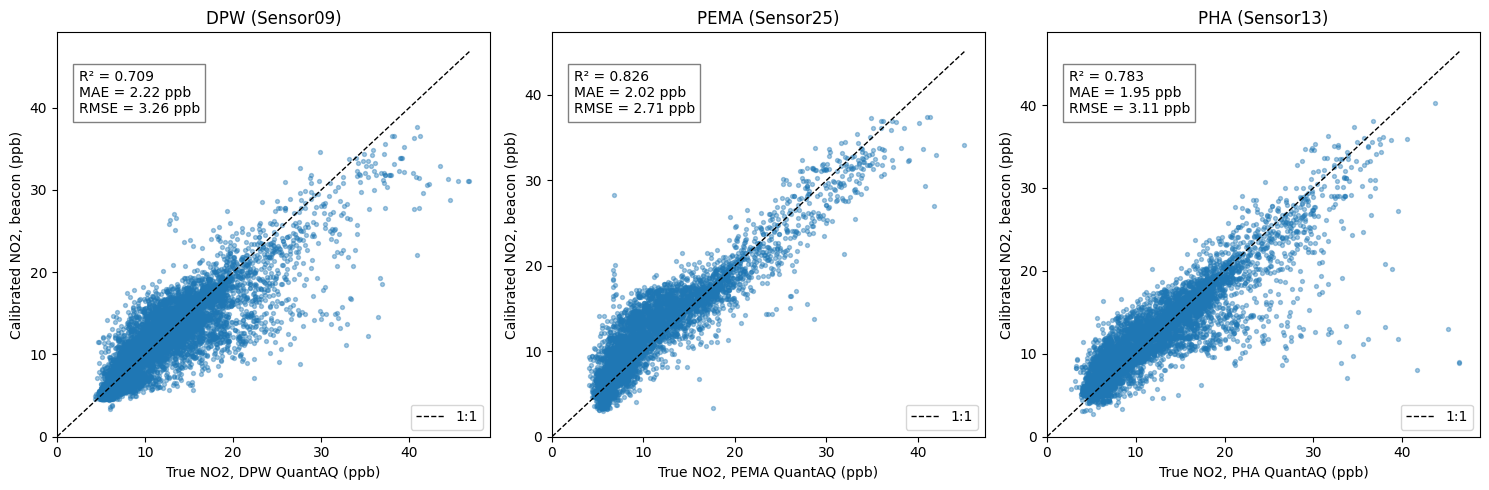

In [ ]:
from pathlib import Path
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

data_folder = Path("training and testing datasets")
features = ["co_wrk_aux", "no2_wrk_aux", "no_wrk_aux", "o3_wrk_aux", "rh", "temp"]

SENSORS = {
    "Sensor01": ("Myron J. Francis Elementary", 250),
    "Sensor02": ("Silver Lake Residence", 254),
    "Sensor03": ("Reservoir Ave Elementary", 258),
    "Sensor04": ("Anthony Carnevale Elementary", 261),
    "Sensor05": ("E-Cubed Academy Senior High", 264),
    "Sensor06": ("Rochambeau Library", 267),
    "Sensor07": ("Smith Hill Library", 270),
    "Sensor08": ("Alpert Medical School", 274),
    "Sensor09": ("Department of Public Works", 276),
    "Sensor10": ("Zuccolo Recreation Center", 251),
    "Sensor11": ("West End Community Center", 252),
    "Sensor12": ("United Way", 255),
    "Sensor13": ("Providence Housing Authority", 257),
    "Sensor14": ("CCRI - Liston Campus", 259),
    "Sensor15": ("Main St. Martial Arts", 262),
    "Sensor16": ("South Providence Library", 263),
    "Sensor17": ("Blackstone Residence", 266),
    "Sensor18": ("Brown-Fox Point Early Childhood Learning Center", 269),
    "Sensor19": ("Rock Spot Climbing Gym", 272),
    "Sensor20": ("Rockefeller Library", 253),
    "Sensor21": ("Child & Family Services", 256),
    "Sensor22": ("Mt. Pleasant Hardware", 260),
    "Sensor23": ("Rhode Island College", 265),
    "Sensor24": ("Providence College", 268),
    "Sensor25": ("Providence Emergency Management Agency", 271)
}

collocated = {"Sensor09": "dpw", "Sensor25": "pema", "Sensor13": "pha"}

sensor_ids = [i for i in range(2, 26) if i != 17]

results = []
test_preds = {}
all_preds = {}

for i in sensor_ids:
    name = f"Sensor{i:02d}"
    train_path = data_folder / f"{name.lower()}training.csv"
    test_path = data_folder / f"{name.lower()}testing.csv"
    
    if not (train_path.exists() and test_path.exists()):
        print(f"Skipping {name}: files not found")
        continue
    
    train = pd.read_csv(train_path, parse_dates=["datetime_utc"])
    test = pd.read_csv(test_path, parse_dates=["datetime_utc"])
    
    target = [c for c in train.columns if c not in features + ["datetime_utc"]][0]
    
    model = XGBRegressor(
        n_estimators=150,
        max_depth=2,
        learning_rate=0.1,
        subsample=1.0,
        colsample_bytree=0.8,
        random_state=42,
    )
    model.fit(train[features], train[target])
    
    test_pred = model.predict(test[features])
    train_r2 = r2_score(train[target], model.predict(train[features]))
    test_r2 = r2_score(test[target], test_pred)
    test_mae = mean_absolute_error(test[target], test_pred)
    test_rmse = np.sqrt(mean_squared_error(test[target], test_pred))
    
    results.append({
        "Sensor": name,
        "Location": SENSORS[name][0],
        "Reference site": target.upper(),
        "Train R^2": round(train_r2, 3),
        "Test R^2": round(test_r2, 3),
        "Test MAE": round(test_mae, 3),
        "Test RMSE": round(test_rmse, 3),
        "Train rows": len(train),
    })
    
    all_preds[name] = pd.Series(test_pred, index=test["datetime_utc"])
    
    if name in collocated:
        test_preds[name] = (test["datetime_utc"], test[target], test_pred, test_r2, test_mae, test_rmse)

results_df = pd.DataFrame(results)
display(results_df)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, site) in zip(axes, collocated.items()):
    if name not in test_preds:
        ax.set_title(f"{site.upper()} ({name}): no data")
        continue
    _, true, pred, r2, mae, rmse = test_preds[name]
    ax.scatter(true, pred, s=8, alpha=0.4)
    lim = max(true.max(), pred.max())
    ax.plot([0, lim], [0, lim], "k--", linewidth=1, label="1:1")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.set_xlabel(f"True NO2, {site.upper()} QuantAQ (ppb)")
    ax.set_ylabel("Calibrated NO2, beacon (ppb)")
    ax.set_title(f"{site.upper()} ({name})")
    ax.text(0.05, 0.80, f"R² = {r2:.3f}\nMAE = {mae:.2f} ppb\nRMSE = {rmse:.2f} ppb",
            transform=ax.transAxes, bbox=dict(facecolor="white", edgecolor="gray"))
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
out_folder = Path("final csv")

column_names = {
    "Sensor01": "MJF Elementary",
    "Sensor02": "Silver Lake",
    "Sensor03": "Reservoir Ave",
    "Sensor04": "Carnevale",
    "Sensor05": "E-Cubed",
    "Sensor06": "Rochambeau",
    "Sensor07": "Smith Hill",
    "Sensor08": "Alpert Med",
    "Sensor09": "DPW",
    "Sensor10": "Zuccolo",
    "Sensor11": "West End",
    "Sensor12": "United Way",
    "Sensor13": "PHA",
    "Sensor14": "CCRI",
    "Sensor15": "Main St MA",
    "Sensor16": "South Prov",
    "Sensor17": "Blackstone",
    "Sensor18": "Brown-Fox Point",
    "Sensor19": "Rock Spot",
    "Sensor20": "Rockefeller",
    "Sensor21": "Child & Family",
    "Sensor22": "Mt. Pleasant",
    "Sensor23": "RIC",
    "Sensor24": "Providence College",
    "Sensor25": "PEMA",
}

cal = pd.DataFrame(all_preds).reindex(columns=list(column_names.keys()))
cal = cal.sort_index().round(2)
cal.index.name = "datetime_utc"
cal = cal.rename(columns=column_names)

fmt = "%Y-%m-%d %H:%M:%S"
final = cal.reset_index()
utc = final["datetime_utc"]
final.insert(1, "datetime_est", (utc - pd.Timedelta(hours=5)).dt.strftime(fmt))
final.insert(2, "datetime_edt", (utc - pd.Timedelta(hours=4)).dt.strftime(fmt))
final["datetime_utc"] = utc.dt.strftime(fmt)

final.to_csv(out_folder / "final_calibrated_no2.csv", index=False)
print(f"Saved {len(final)} rows, {final.shape[1]} columns")
final.head()

Saved 7195 rows, 28 columns


,datetime_utc,datetime_est,datetime_edt,MJF Elementary,Silver Lake,Reservoir Ave,Carnevale,E-Cubed,Rochambeau,Smith Hill,...,South Prov,Blackstone,Brown-Fox Point,Rock Spot,Rockefeller,Child & Family,Mt. Pleasant,RIC,Providence College,PEMA
0,2025-01-01 00:00:00,2024-12-31 19:00:00,2024-12-31 20:00:00,NaN,27.020000,NaN,25.540001,25.000000,22.549999,25.219999,...,23.799999,NaN,21.440001,24.629999,24.570000,23.230000,23.520000,20.760000,26.190001,26.520000
1,2025-01-01 01:00:00,2024-12-31 20:00:00,2024-12-31 21:00:00,NaN,31.219999,NaN,24.990000,29.559999,21.600000,26.270000,...,24.959999,NaN,21.570000,22.070000,24.190001,24.799999,26.209999,21.639999,27.250000,27.969999
2,2025-01-01 02:00:00,2024-12-31 21:00:00,2024-12-31 22:00:00,NaN,26.120001,NaN,28.139999,27.280001,20.030001,26.700001,...,22.570000,NaN,19.549999,21.440001,24.120001,22.590000,24.120001,21.320000,25.440001,24.950001
3,2025-01-01 03:00:00,2024-12-31 22:00:00,2024-12-31 23:00:00,NaN,22.190001,NaN,24.719999,20.840000,16.629999,22.540001,...,20.620001,NaN,17.650000,21.600000,19.520000,18.570000,19.910000,19.410000,20.740000,18.230000
4,2025-01-01 04:00:00,2024-12-31 23:00:00,2025-01-01 00:00:00,NaN,19.459999,NaN,20.709999,17.090000,13.400000,19.620001,...,17.860001,NaN,13.180000,14.540000,14.280000,15.030000,17.370001,17.889999,18.879999,15.060000
